In [1]:
# DG L = 3 这个参数结果不是想要的。

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.sparse import csr_matrix
import scvelo as scv
from torch.optim import SGD, Adam, Adagrad
from function import *

from utils import *
from g2g_model_Fisher import *
import itertools

In [3]:
data_path = "/home/linux/桌面/SCIM-main/main/data/branch_data/"
path_path = "/home/linux/桌面/Is single cell sloppy?/4_FI_vs_Velocity/RC_path/"
cmap = plt.colormaps['Spectral_r']
save = False

[k_nei, K, L] = [10, 3, 3]
computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 3139 × 678
    obs: 'Age', 'Cell_Conc', 'ChipID', 'ClusterName', 'celltype', 'Comments', 'Date_Captured', 'DonorID', 'Label', 'NGI_PlateWell', 'Num_Pooled_Animals', 'PCR_Cycles', 'Plug_Date', 'Project', 'SampleID', 'SampleOK', 'Sample_Index', 'Seq_Comment', 'Seq_Lib_Date', 'Seq_Lib_Ok', 'Serial_Number', 'Sex', 'Species', 'Strain', 'TSNE1', 'TSNE2', 'Target_Num_Cells', 'Tissue', 'Transcriptome', 'cDNA_Lib_Ok', 'ngperul_cDNA', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition

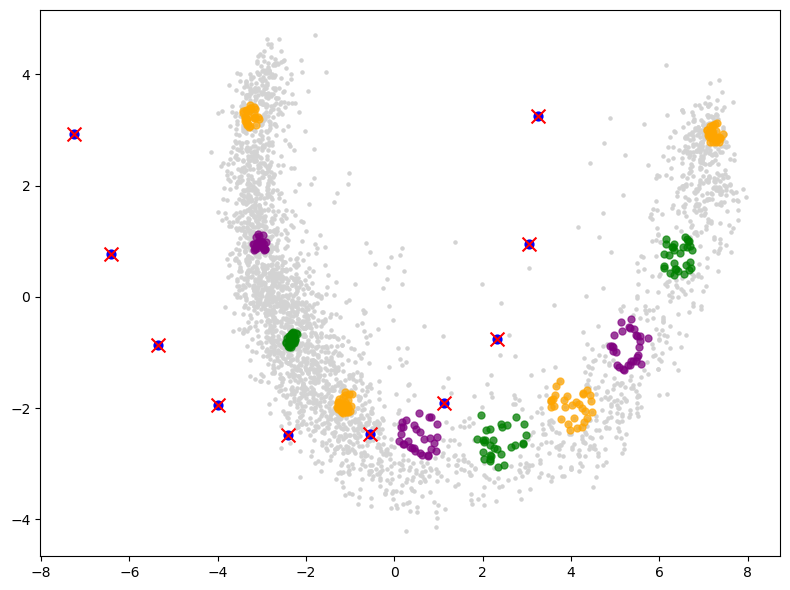

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

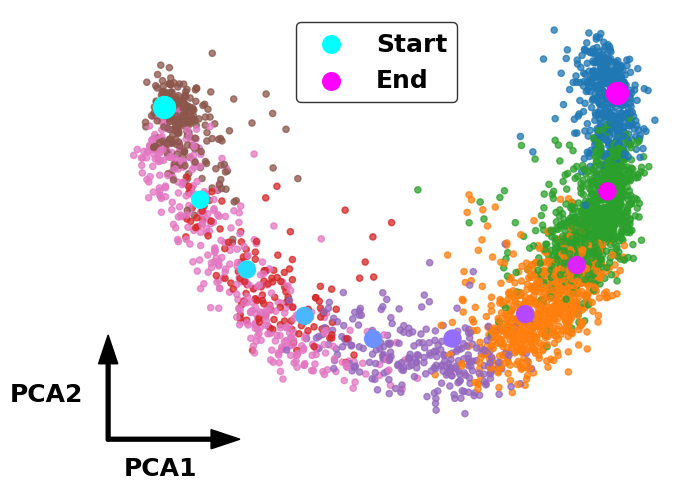

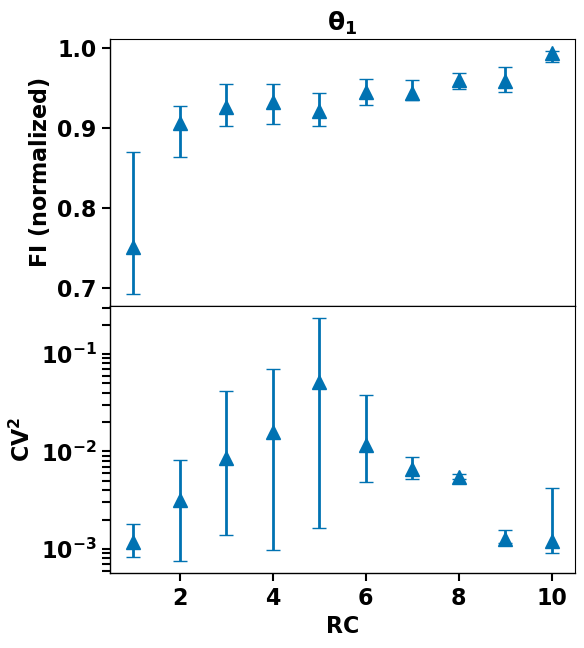

y: [0.0011904  0.00316867 0.00858689 0.01571087 0.05182641 0.01152191
 0.0066795  0.00542146 0.00126759 0.00119402]
max_vals: [0.00181459 0.00819883 0.04131891 0.07061674 0.23205894 0.03823105
 0.00882243 0.005915   0.00154852 0.00420123]
min_vals: [0.00081965 0.00074949 0.00140016 0.00096948 0.00165326 0.00487082
 0.00519657 0.00517077 0.00114841 0.00091339]
error: [[3.7075201e-04 2.4191828e-03 7.1867364e-03 1.4741383e-02 5.0173156e-02
  6.6510825e-03 1.4829258e-03 2.5068643e-04 1.1918112e-04 2.8063537e-04]
 [6.2418566e-04 5.0301533e-03 3.2732017e-02 5.4905877e-02 1.8023252e-01
  2.6709147e-02 2.1429304e-03 4.9354089e-04 2.8092740e-04 3.0072075e-03]]
y: [2.5388196e-03 1.1035050e-02 2.7229579e-02 6.0194831e-02 7.7015258e-02
 1.7240387e-01 1.5335834e+02 4.4574425e-01 1.8681580e-01 4.4438023e-02]
max_vals: [3.4367088e-03 2.7881157e-02 1.4130093e-01 2.2782148e-01 3.7921351e-01
 2.8359297e-01 4.2503926e+03 1.6075647e+00 3.3621591e-01 1.5786196e-01]
min_vals: [0.00205892 0.00402801 0.009716

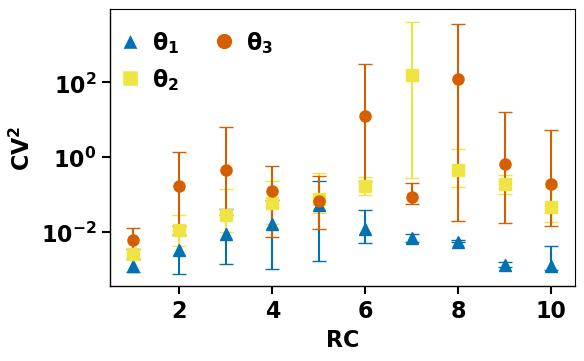

pca_svd_rc_mean_all:
[[[-1.43847284e+01 -1.88757973e+01  1.67326336e+01]
  [ 1.41186485e+01  1.89419327e+01 -1.69082184e+01]
  [-1.57546959e+01 -1.71468487e+01 -1.46482725e+01]
  [-1.59341612e+01 -1.70824814e+01 -1.45315609e+01]
  [-1.62497272e+01 -1.67036724e+01  1.10749187e+01]
  [ 1.38970842e+01  1.89040432e+01 -1.77544136e+01]
  [-1.45740108e+01 -1.88341370e+01  1.66395550e+01]
  [-1.64396191e+01 -2.06690540e+01 -1.03154421e+01]
  [-1.54465141e+01 -1.72517090e+01 -1.48360224e+01]
  [ 1.41169939e+01  2.02805786e+01 -1.59061756e+01]
  [-1.46479635e+01 -1.98935795e+01  1.51022940e+01]
  [-1.57666082e+01 -1.71384869e+01 -1.46133099e+01]
  [-1.70818272e+01 -1.98720932e+01 -9.85956097e+00]
  [-1.66449966e+01 -2.08727303e+01 -9.89929104e+00]
  [ 1.04074192e+01 -2.38422527e+01 -1.67147293e+01]
  [-1.56858673e+01 -1.71665039e+01 -1.46623440e+01]
  [ 1.40005751e+01  1.95571060e+01 -1.75528793e+01]
  [ 1.30842791e+01  2.06752548e+01 -1.68106003e+01]
  [-1.64177589e+01 -2.06952076e+01 -1.03711

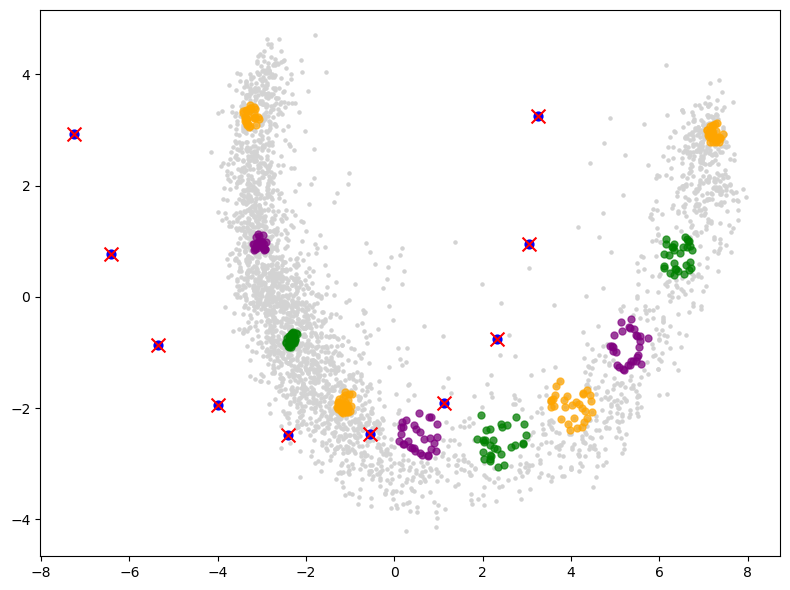

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

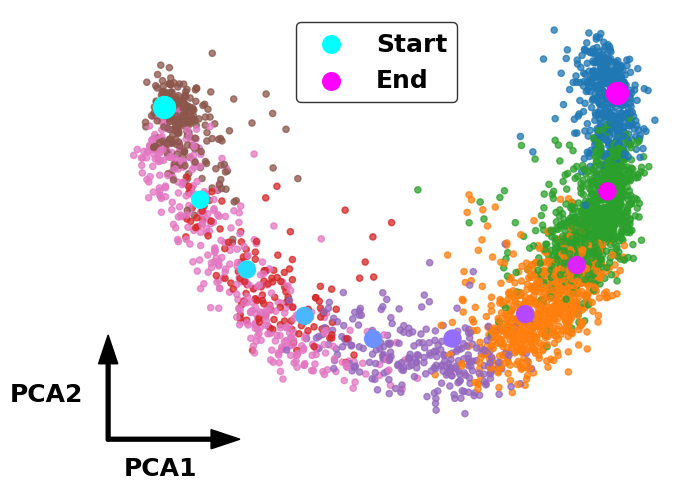

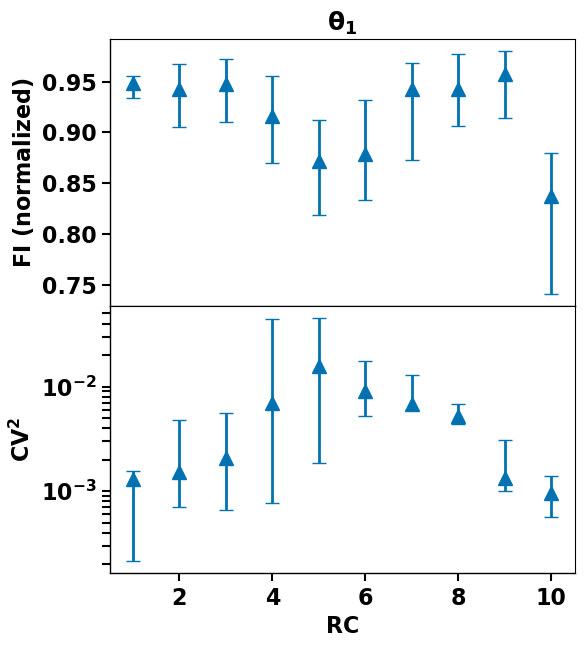

y: [0.00129571 0.00152388 0.00208846 0.00690104 0.01584809 0.00897295
 0.00679312 0.00526893 0.00134022 0.00096508]
max_vals: [0.00155245 0.00481093 0.00560316 0.04402668 0.04483255 0.01761049
 0.01283325 0.00686846 0.0031102  0.00140275]
min_vals: [0.00021378 0.0006975  0.00065389 0.00077482 0.00185522 0.00520145
 0.00590935 0.0043676  0.00100084 0.00056176]
error: [[0.00108192 0.00082638 0.00143457 0.00612621 0.01399287 0.0037715
  0.00088377 0.00090133 0.00033937 0.00040332]
 [0.00025674 0.00328705 0.0035147  0.03712565 0.02898446 0.00863754
  0.00604013 0.00159953 0.00176999 0.00043767]]
y: [4.0319585e-03 1.1772614e-01 7.5720468e+00 1.4010252e+01 2.2732483e+03
 7.4698433e+01 2.1562321e+00 5.4730362e-01 5.6044746e+01 2.9989468e+02]
max_vals: [6.1204699e-03 3.0651033e-01 1.4557808e+02 3.4885126e+02 6.8036711e+04
 1.8269523e+03 2.4001028e+01 1.3694829e+01 1.6422206e+03 1.8653872e+03]
min_vals: [0.00339591 0.02232956 0.12861928 0.0639625  0.06425346 0.33931
 0.1141785  0.03757932 0.030

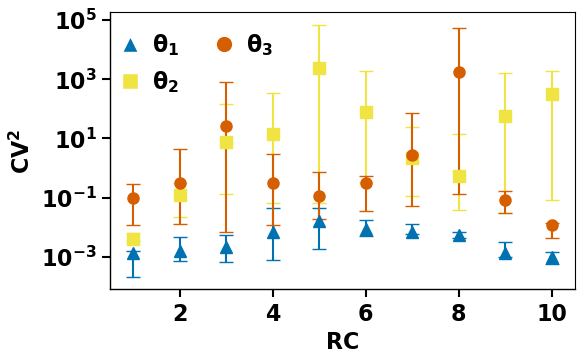

pca_svd_rc_mean_all:
[[[-2.10832329e+01 -2.17689381e+01 -2.15143919e+00]
  [-2.10131397e+01 -2.19151630e+01 -1.11554158e+00]
  [-1.75090981e+01 -2.40609875e+01  4.61040306e+00]
  [-1.80942497e+01 -2.38901176e+01  1.43918884e+00]
  [-1.82742386e+01 -2.37099857e+01 -5.17374992e+00]
  [-2.10860271e+01 -2.18222942e+01 -1.32376063e+00]
  [-1.88179493e+01 -2.28674355e+01 -6.26503754e+00]
  [-2.12802525e+01 -2.13719406e+01  1.34076440e+00]
  [-1.87476749e+01 -2.34569378e+01  2.26420093e+00]
  [-1.92643032e+01 -2.23789501e+01 -5.48365831e+00]
  [-2.12004814e+01 -2.13209896e+01  2.64403534e+00]
  [-1.94901352e+01 -2.26499557e+01  4.58736372e+00]
  [-2.14031868e+01 -2.11939163e+01  1.66356635e+00]
  [-2.11215343e+01 -2.14252357e+01  2.56086373e+00]
  [-1.76273975e+01  2.33615360e+01  3.69422960e+00]
  [-1.77218437e+01 -2.41886997e+01  2.73098445e+00]
  [-1.97042847e+01 -2.26036873e+01  2.48243356e+00]
  [-2.09189110e+01 -2.15317173e+01  1.80125725e+00]
  [-2.16180611e+01 -2.13246727e+01  2.25248

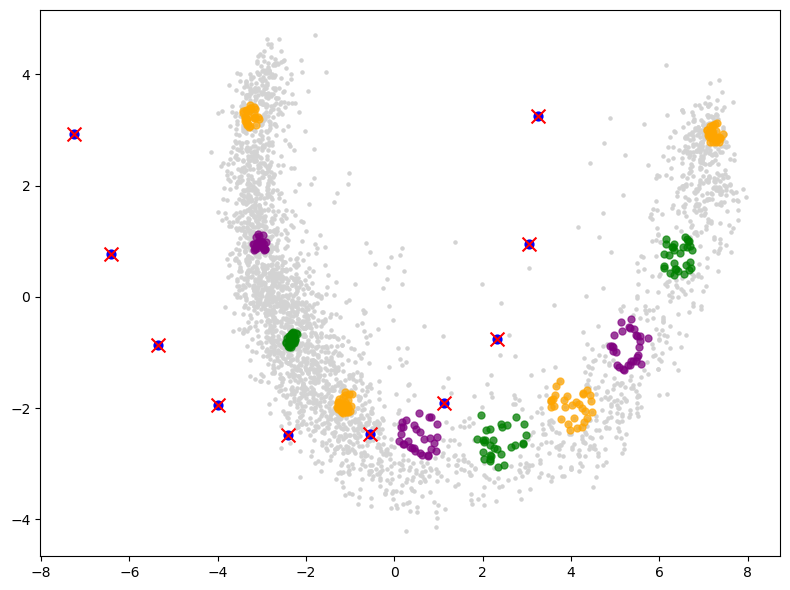

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

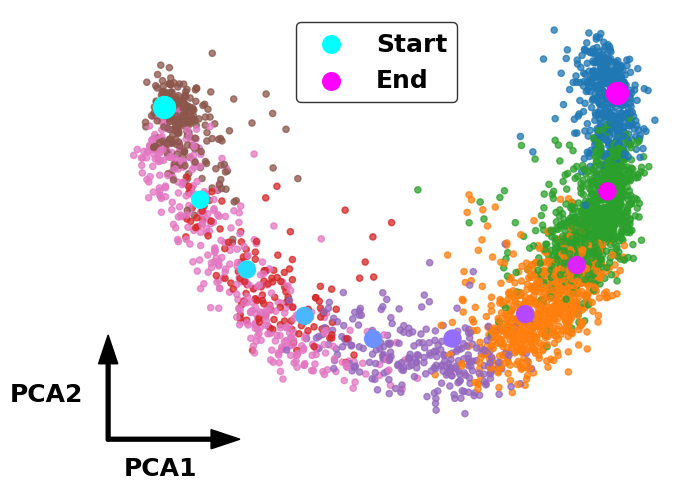

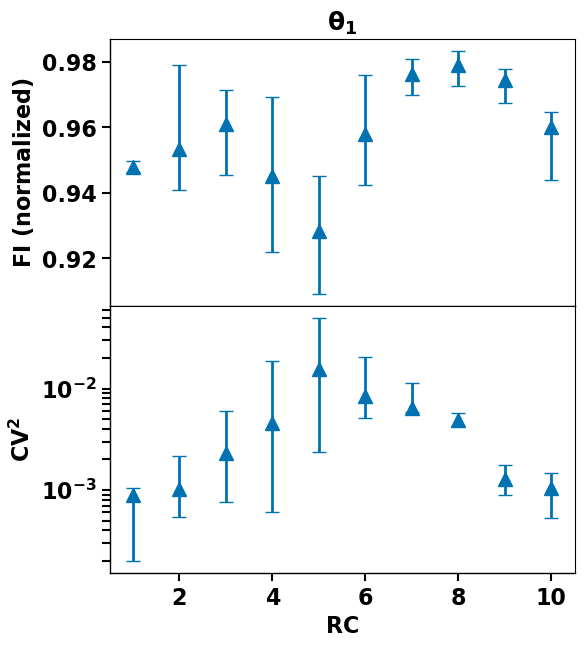

y: [0.0009019  0.00101576 0.002316   0.00460908 0.01545243 0.00850786
 0.00636002 0.00493533 0.00129288 0.00105393]
max_vals: [0.00104125 0.0021766  0.00595842 0.01851293 0.0491875  0.02038568
 0.01123455 0.00579711 0.00175318 0.0014566 ]
min_vals: [0.00019901 0.00054778 0.00075542 0.00061237 0.00238902 0.00509341
 0.00580881 0.00431219 0.00090042 0.0005354 ]
error: [[0.00070289 0.00046799 0.00156058 0.00399671 0.01306341 0.00341445
  0.00055121 0.00062314 0.00039246 0.00051853]
 [0.00013936 0.00116084 0.00364243 0.01390385 0.03373507 0.01187781
  0.00487453 0.00086177 0.0004603  0.00040267]]
y: [2.9144664e-03 3.5478849e-02 9.5795050e-02 3.3535388e-01 3.5657912e-01
 6.3249439e-01 7.0598877e+03 6.4318791e-02 3.2068960e-02 7.8776143e-03]
max_vals: [5.5230637e-03 6.4427510e-02 3.1489652e-01 1.3488344e+00 3.8346770e+00
 2.1598136e+00 2.0940156e+05 1.1790164e-01 4.8837211e-02 1.0864411e-02]
min_vals: [0.00271776 0.0175293  0.02225097 0.04376791 0.02429445 0.15558688
 0.35608846 0.04469839 0

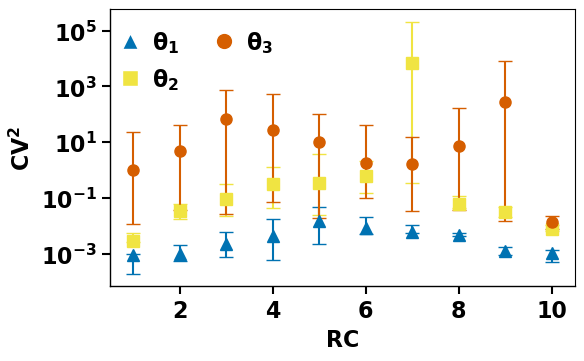

pca_svd_rc_mean_all:
[[[-1.50415154e+01 -2.68634472e+01  1.89473963e+00]
  [-1.52498274e+01 -2.66091232e+01  8.23644996e-01]
  [-1.49509020e+01 -2.69745865e+01  3.36658645e+00]
  [-1.48180904e+01 -2.69454765e+01  2.35190535e+00]
  [-1.53676825e+01 -2.65443764e+01  7.19646215e-01]
  [-1.50986662e+01 -2.68278522e+01  1.96004295e+00]
  [-1.45572290e+01 -2.71284962e+01  4.55005836e+00]
  [-1.50308619e+01 -2.66752644e+01 -6.11706972e-01]
  [-1.48749409e+01 -2.70282364e+01  3.26778173e+00]
  [-1.49480324e+01 -2.70985432e+01  3.33874583e+00]
  [-1.50107899e+01 -2.69473896e+01 -1.58926749e+00]
  [-1.50800304e+01 -2.68389492e+01  1.94622874e+00]
  [-1.51630201e+01 -2.65817356e+01  9.99949127e-02]
  [-1.51273441e+01 -2.67771206e+01  5.21929204e-01]
  [-1.66971588e+01  2.61100254e+01 -4.62679815e+00]
  [-1.48706656e+01 -2.69024734e+01  2.44124842e+00]
  [-1.51873045e+01 -2.67514267e+01  2.31802034e+00]
  [-1.48767900e+01 -2.69000950e+01  2.46646929e+00]
  [-1.53722754e+01 -2.65210381e+01 -3.24578

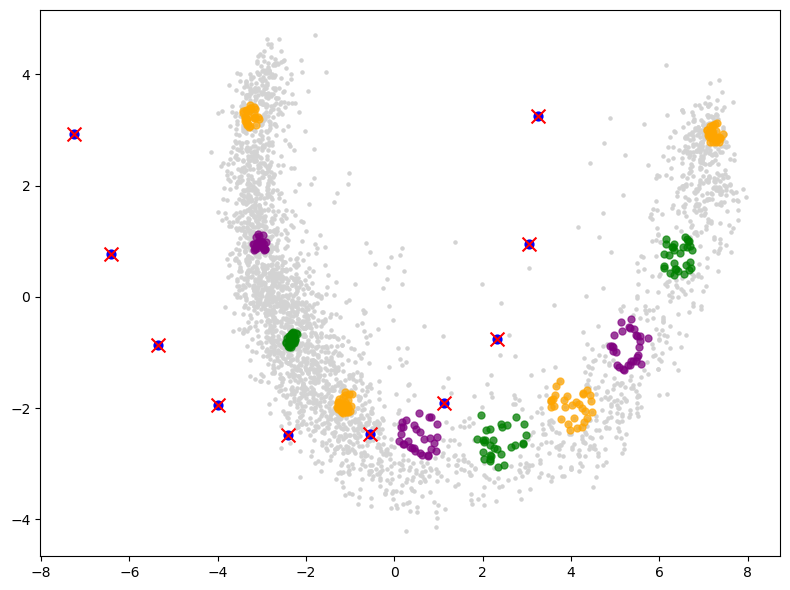

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

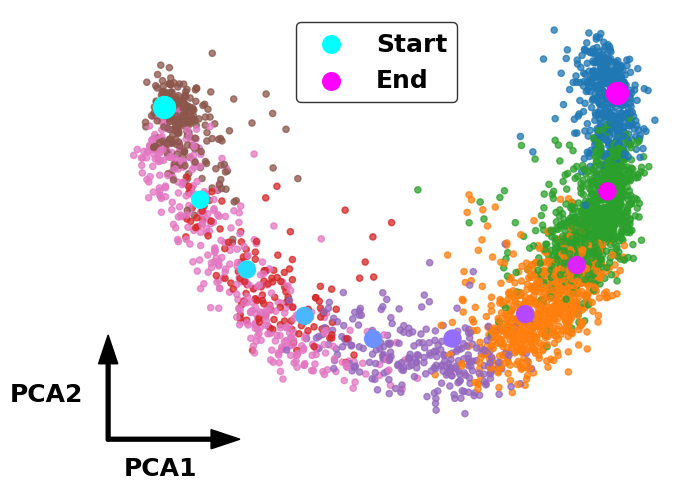

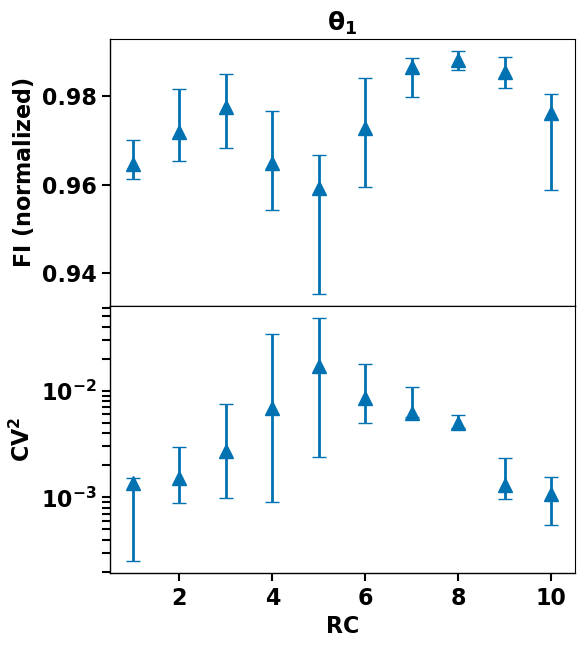

y: [0.00137037 0.00150643 0.00271039 0.00693394 0.01714966 0.0085795
 0.00617249 0.00493561 0.00131505 0.00107152]
max_vals: [0.00152744 0.00296743 0.00751483 0.03450002 0.04794255 0.01778481
 0.01089649 0.00590827 0.00233074 0.00155324]
min_vals: [0.00025099 0.00088296 0.00097968 0.0009063  0.00236368 0.00501141
 0.00566468 0.00451131 0.00096144 0.00054914]
error: [[0.00111938 0.00062347 0.00173071 0.00602765 0.01478598 0.00356809
  0.00050781 0.00042431 0.00035362 0.00052238]
 [0.00015706 0.001461   0.00480444 0.02756608 0.03079289 0.00920531
  0.004724   0.00097265 0.00101568 0.00048172]]
y: [3.8886226e-03 6.3202851e-02 1.4514080e-01 1.0488498e-01 3.5505876e-01
 6.9734317e-01 1.6253553e+04 1.4004961e-01 4.2462107e-02 8.0114873e-03]
max_vals: [6.1681615e-03 1.2978065e-01 9.1162610e-01 2.0462601e-01 2.7543116e+00
 4.6097784e+00 2.7307650e+05 3.4723890e-01 5.4679669e-02 9.0347454e-03]
min_vals: [0.00336841 0.02068975 0.0380637  0.04509464 0.03948775 0.16423652
 0.5754993  0.08040504 0.

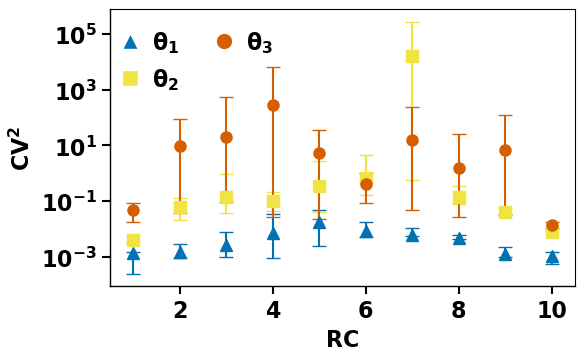

pca_svd_rc_mean_all:
[[[-2.06720028e+01 -2.23062725e+01 -8.99828017e-01]
  [-2.08867302e+01 -2.28084698e+01  1.10736895e+00]
  [-2.08390026e+01 -2.23740788e+01  1.30006230e+00]
  [-2.08217335e+01 -2.23937817e+01  1.32987738e+00]
  [-2.09242115e+01 -2.24691544e+01  2.61998057e+00]
  [-2.08451004e+01 -2.23693600e+01  1.31564343e+00]
  [-2.07617569e+01 -2.21933060e+01  1.55485129e+00]
  [-2.06715221e+01 -2.23065090e+01 -8.90778542e-01]
  [-2.07591820e+01 -2.26973991e+01  1.63276851e+00]
  [-2.07922459e+01 -2.21700039e+01  1.57038474e+00]
  [-2.06250877e+01 -2.20465469e+01  8.89129221e-01]
  [-2.08447838e+01 -2.23705406e+01  1.33349359e+00]
  [-2.06856346e+01 -2.22980747e+01 -8.91256750e-01]
  [-2.06644688e+01 -2.23145580e+01  8.61395121e-01]
  [-1.92193489e+01  2.45886936e+01 -1.67387605e+00]
  [-2.07651100e+01 -2.26893349e+01  1.64203143e+00]
  [-2.08514977e+01 -2.23685856e+01  1.30475485e+00]
  [-2.08084278e+01 -2.21579227e+01  1.54712677e+00]
  [-2.07027626e+01 -2.22803326e+01 -8.99423

In [4]:
k_nei_list = [10]
K_list = [3]
L_list = [3, 6, 10, 15]

param_combinations = list(itertools.product(k_nei_list, K_list, L_list))

for k_nei, K, L in param_combinations:
    [k_nei, K, L] = [k_nei, K, L]
    data_name = "DG_bin_ppt"
    print(f"[k_nei, K, L] = [{k_nei}, {K}, {L}]")
    figure_path= f"/home/linux/桌面/Is single cell sloppy?/14_画图/figure/cv_2/{data_name}/" + str([k_nei,K,L]) + "/"

    [pca_dim, k_rc, d_pca, nrc] = [50, 30, 2, 10]

    clusters_name = "ClusterName"
    root_cluster = "RadialGlia"
    loc_path_graph = 'upper left'
    basis = "pca"

    t_list = np.array(['RadialGlia','nIPC', 'Nbl1', 'Nbl2', 'ImmGranule1', 'ImmGranule2', 'Granule' ])
    branch_name = t_list[-1]

    adata0 = scv.read(data_path+data_name+'.h5ad', cache=True)
    adata = adata0.copy()
    scv.pp.pca(adata, n_comps=pca_dim)
    scv.pp.neighbors(adata, n_neighbors=k_nei)
    scv.pp.moments(adata, n_pcs=pca_dim, n_neighbors=k_nei)
    scv.tl.velocity(adata)
    print(adata)

    for nrc in [10]:
        # average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        average_path = np.load(path_path + f'{data_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, rc_distance= "X_pca", n_nei=k_rc, dim_n=d_pca)            
        average_path[:,0] = -average_path[:,0]


        # fig = sc.pl.embedding(
        #     adata,
        #     # color=[clusters_name, "paga"],
        #     color=[clusters_name],
        #     basis="pca",
        #     color_map=cmap,
        #     return_fig=True
        # )

        X_pca = adata.obsm['X_pca']
        row = np.array([np.ones((k_nei,))*i for i in range(adata.shape[0])]).flatten()
        col = adata.uns['neighbors']['indices'].flatten()
        w_val = np.array([np.linalg.norm(X_pca[int(i),:]-X_pca[int(j),:]) for i,j in zip(row,col)])
        adj_val = np.ones(col.shape)
        A_mat = csr_matrix((adj_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
        A = A_mat
        W_mat = csr_matrix((w_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
        dc=np.mean(w_val)
        cell_nei=adata.uns['neighbors']['indices']
        nei_w=[]
        rho_arr=[]
        for ni in adata.uns['neighbors']['indices']:
            dij=np.array([np.linalg.norm(X_pca[int(ni[0]),:]-X_pca[int(i),:]) for i in ni[1:]])
            rho=np.sum(np.exp(-dij**2/dc**2))
            nei_w.append(np.exp(-dij**2/dc**2)/np.sum(np.exp(-dij**2/dc**2)))
            rho_arr.append(rho)
            
        rho_arr=np.array(rho_arr)/np.amax(rho_arr)
        nei_w=np.array(nei_w)
        nei_w=np.hstack((np.ones((nei_w.shape[0],1)),nei_w))/2

        def smooth_func(X_val,cell_nei=cell_nei,nei_w=nei_w):
            X_s=X_val.copy()
            for ci in range(len(X_val)):
                X_s[ci]=np.dot(X_val[cell_nei[ci,:]],nei_w[ci,:])
            return X_s

        if basis == "umap":
            X_umap = adata.obsm['X_umap']
            X_plt = X_umap[:,0]
            Y_plt = X_umap[:,1]
            X_min = np.min(X_plt)
            X_max = np.max(X_plt)
            Y_min = np.min(Y_plt)
            Y_max = np.max(Y_plt)
            X_len = (X_max-X_min)/5
            Y_len = (Y_max-Y_min)/5
            wid = min(X_len,Y_len)/30
            X_ori = X_min-wid*10
            Y_ori = Y_min-wid*10
        elif basis == "pca":
            X_umap = adata.obsm['X_pca'][:, :2]
            X_plt = X_umap[:,0]
            Y_plt = X_umap[:,1]
            X_min = np.min(X_plt)
            X_max = np.max(X_plt)
            Y_min = np.min(Y_plt)
            Y_max = np.max(Y_plt)
            X_len = (X_max-X_min)/5
            Y_len = (Y_max-Y_min)/5
            wid = min(X_len,Y_len)/30
            X_ori = X_min-wid*10
            Y_ori = Y_min-wid*10

        X = torch.tensor(adata.layers['Ms'], dtype=torch.float32) 
        Encoder_path = "/home/linux/桌面/Is single cell sloppy?/11_PAGA_spectrum/encoder/"
        # for pca in [X_pca, eigengene, hotspot]:

        model_path = Encoder_path + data_name+' '+str([k_nei,K,L])+'/'
        # eigengene = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_eigengene_X.npy")
        hotspot = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_hs_X.npy")
        model_name = f"{model_path}encoder.pt"
        model = torch.load(f'{model_name}')
        mu, sigma = model(torch.tensor(X))
        mu_learned = mu.detach().numpy()

        sigma_learned = sigma.detach().numpy()
        Fisher_g=np.zeros((X.shape[0],L*2,L*2))
        for i in range(X.shape[0]):
            for j in range(L):
                Fisher_g[i,j,j]=1/sigma_learned[i,j]**2
                Fisher_g[i,L+j,L+j]=2/sigma_learned[i,j]**2
        Fisher_g_diag = np.zeros([X.shape[0],L*2])
        for i in range(X.shape[0]):
            Fisher_g_diag[i] = np.diag(Fisher_g[i])
        ## 1_1这一步用了一个神经网络 pca -> Z(mu,sigma), 然后求出这个网络的pZ_pEg。
        for pca in [hotspot]:
            print("pca.shape:", pca.shape)
            reset_seeds(0) # 0
            model = nn.Sequential(
                nn.Linear(pca.shape[1], 128),
                nn.ReLU(),
                nn.Linear(128,64),
                nn.ReLU(),
                nn.Linear(64,2*L),
            )
            loss_fn = nn.MSELoss()
            optimizer = SGD(model.parameters(), lr=0.01, weight_decay=0.001)#, momentum=0.2
            x_in=torch.tensor(pca, dtype=torch.float32)
            latent_z = np.hstack((mu_learned,sigma_learned))
            x_out=torch.tensor(latent_z.astype(np.float32))
            for epoch in range(500): # 200
                # break
                optimizer.zero_grad()
                output = model(x_in)
                loss = loss_fn(output,x_out) 
                loss.backward()
                optimizer.step()
            pZ_ppca = p_out_p_in(pca, model, dim_out = 2 * L)

            ### 链式法则（已知FI_Z），求出FI_pca。
            FI_pca = np.einsum("ijk,ij,ijh->ikh",pZ_ppca, Fisher_g_diag, pZ_ppca)
            print("FI_pca.shape:", FI_pca.shape)
            # FI_Eg_diag = FI_Eg[:, range(eigengene.shape[1]), range(eigengene.shape[1])]
            # U_FI_Eg[i]的列向量是特征向量。Ax = /lamba x (从这可以看出x是列向量)
            # 不过U_FI_Eg[i]的行向量和列向量的模长都是1.而且行和行彼此正交。列和列彼此正交。这是因为UU_T = I. U是正交矩阵。
            U_FI_Eg, S_FI_Eg, Vt_FI_Eg = np.linalg.svd(FI_pca, full_matrices=False)
            print("svd后(U_FI_Eg, S_FI_Eg, Vt_FI_Eg)：",U_FI_Eg.shape, S_FI_Eg.shape, Vt_FI_Eg.shape)
            print("S_FI_Eg:", S_FI_Eg)

            # rc_path(adata, mu_learned, sigma_learned, average_path, basis, k_nei, data_name)
            cell_arr_plot(average_path, cell_arr, X_umap)
            rc_path_celltype(adata, average_path, basis, data_name, save = save, figure_path = figure_path, branch_name  = branch_name)
                
            dim = 3
            # U_FI_Eg和pca的各列都是正交的才可以这么算。cell_i_的pca坐标（向量）点积u1得到的就是u1的坐标，这其实就是在u1上做投影。
            # NOTE:这可能是为什么eigengene和hotspot不行的原因，eigengene的各坐标系间不是正交的。
            pca_svd_rc_variance_all, pca_svd_rc_mean_all= compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L, simple=dim/2, cv= True)
            pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
            # plot_all_variances_odd(pca_svd_rc_variance_all, share_y = False)
            FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, L = 0.5, cell_arr = cell_arr, norm=True, simple= True, 
                            save = save, figure_path = figure_path, branch_name  = branch_name)

            exclude_indices = []
            all_indices = list(range(len(pca_svd_rc_variance_all)))
            keep_indices = [i for i in all_indices if i not in exclude_indices]
            new_array = np.array(pca_svd_rc_variance_all)[keep_indices]

            variance_along_rc(cell_arr, new_array, dim = dim, save = save, figure_path = figure_path, branch_name  = branch_name)

            print("pca_svd_rc_mean_all:")
            print(np.array(pca_svd_rc_mean_all))

In [5]:
# 幂法
# print(top_k_eigenpairs(FI_pca, k=7))
# print("U_FI_Eg", U_FI_Eg)
# print("S_FI_Eg", S_FI_Eg)

# # PART 3------show一下RC path
# rc_num = average_path.shape[0]
# cells_visual = adata.obsm[f'X_pca'][:, :2]
# # 只取3种颜色，然后循环使用
# base_colors = ['orange', 'green', 'purple']
# plt.figure(figsize=(8,6))
# plt.scatter(cells_visual[:,0], cells_visual[:,1], s=5, color='lightgrey', label='All cells')
# plt.scatter(cells_visual[nearest_cell,0], cells_visual[nearest_cell,1], s=40, c='blue', label='Path points')

# for rc_i in range(rc_num):
#     color = base_colors[rc_i % 3]  # 每3种颜色循环
#     plt.scatter(cells_visual[nearest_cell[rc_i],0], cells_visual[nearest_cell[rc_i],1], s=100, c='red', marker='x')
#     plt.scatter(cells_visual[cell_arr[rc_i],0], 
#                 cells_visual[cell_arr[rc_i],1],
#                 s=25, c=[color], alpha=0.7, label=f'RC {rc_i}')

# # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
# plt.title('Nearest 30 cells for all RCs (3-color cycle)')
# plt.tight_layout()
# plt.show() 

# # PART 3------show一下RC path
# rc_num = average_path.shape[0]
# cells_visual = adata.obsm[f'X_{basis}'][:, :2]
# # 只取3种颜色，然后循环使用
# base_colors = ['orange', 'green', 'purple']
# plt.figure(figsize=(8,6))
# plt.scatter(cells_visual[:,0], cells_visual[:,1], s=5, color='lightgrey', label='All cells')
# plt.scatter(cells_visual[nearest_cell,0], cells_visual[nearest_cell,1], s=40, c='blue', label='Path points')

# for rc_i in range(rc_num):
#     color = base_colors[rc_i % 3]  # 每3种颜色循环
#     plt.scatter(cells_visual[nearest_cell[rc_i],0], cells_visual[nearest_cell[rc_i],1], s=100, c='red', marker='x')
#     plt.scatter(cells_visual[cell_arr[rc_i],0], 
#                 cells_visual[cell_arr[rc_i],1],
#                 s=25, c=[color], alpha=0.7, label=f'RC {rc_i}')

# # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
# plt.title('Nearest 30 cells for all RCs (3-color cycle)')
# plt.tight_layout()
# plt.show()


# pca_svd_rc_variance_all = compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L)
# pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
# plot_all_variances(pca_svd_rc_variance_all)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = True)

# pca_svd_rc_variance_all = compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L)
# pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
# plot_all_variances(pca_svd_rc_variance_all)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = True)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = True, simple= True)

# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = False)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = False, simple= True)
# eigengene_value_sum(S_FI_Eg, pca, L, cell_arr)
# eigengene_value(np.array(pca_svd_rc_variance_all), X_pca, L, cell_arr)

# FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, L, cell_arr, norm=True)

In [6]:
pca.shape

(3139, 7)